# EDA BDD100K — dataset mới

Theo proposal hiện tại: **55.000 train / 14.863 held-out test / 10.000 val**. Source daytime-clear; targets night-clear, daytime-rainy và night-rainy.

Notebook chỉ sử dụng artifact EDA từ dataset mới. Annotation test không được đọc trong EDA; test chỉ có metadata census. Báo cáo đầy đủ: `runs/eda_revised/report_vi.html`.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'scripts/eda_revised_bdd100k.py').exists())
DATA = ROOT / 'data/bdd100k_revised'
EDA = ROOT / 'runs/eda_revised'
metadata = json.loads((DATA / 'dataset_metadata.json').read_text(encoding='utf-8'))
summary = json.loads((EDA / 'summary.json').read_text(encoding='utf-8'))
assert (DATA / 'COMPLETE').exists()
assert metadata['counts'] == {'train':55000, 'test':14863, 'val':10000}
assert metadata['integrity']['passed']
assert not summary['heldout_labels_opened_by_eda']
assert summary['dataset_manifest_sha256'] == metadata['manifest_sha256']

def table(name):
    return pd.read_csv(EDA / 'tables' / name)

def figure(name):
    display(Image(filename=str(EDA / 'figures' / name)))

pd.set_option('display.max_columns', 20)
print('Dataset:', DATA)
print('EDA label splits:', summary['eda_label_splits'])

Dataset: D:\cv\data\bdd100k_revised
EDA label splits: ['train', 'val']


## 1. Audit split

Phân tầng theo thời điểm–thời tiết, rồi theo cảnh trong từng ô bằng Hamilton; seed 20260916. Giữ nguyên membership validation chính thức. Kiểm tra cả tên và SHA256 nội dung ảnh giữa các split. 137 ảnh train gốc không có annotation và test công khai không nhãn bị loại khỏi nghiên cứu.

In [2]:
display(pd.Series(metadata['counts'], name='images').to_frame())
display(pd.DataFrame(metadata['integrity']['basename_overlap'], index=['basename_overlap']))
display(pd.DataFrame(metadata['integrity']['sha256_content_overlap'], index=['content_overlap']))
display(pd.DataFrame(summary['split_balance']).T)
print('Dimensions:', metadata['dimensions'])
strata = table('stratification.csv')
display(strata.sort_values('rounding_error', key=abs, ascending=False).head(10))

,images
train,55000
test,14863
val,10000


,train/test,train/val,test/val
basename_overlap,0,0,0


,train/test,train/val,test/val
content_overlap,0,0,0


,total_variation_distance,max_absolute_proportion_difference
timeofday,0.000053,0.000040
weather,0.000181,0.000118
scene,0.000264,0.000153
timeofday/weather/scene,0.001381,0.000062


Dimensions: {'1280x720': 79863}


,timeofday,weather,scene,original_labeled,train,test,ideal_train,rounding_error
86,night,overcast,city street,41,33,8,32.277457,0.722543
123,undefined,undefined,tunnel,72,56,16,56.682364,-0.682364
99,night,snowy,city street,1783,1403,380,1403.675765,-0.675765
18,dawn/dusk,partly cloudy,parking lot,2,1,1,1.574510,-0.574510
10,dawn/dusk,foggy,residential,2,1,1,1.574510,-0.574510
112,undefined,rainy,highway,2,1,1,1.574510,-0.574510
32,dawn/dusk,undefined,parking lot,2,1,1,1.574510,-0.574510
45,daytime,overcast,city street,4407,3470,937,3469.433033,0.566967
77,night,clear,gas stations,7,5,2,5.510785,-0.510785
68,daytime,snowy,undefined,7,5,2,5.510785,-0.510785


## 2. Census và các domain

`undefined` có trong census toàn bộ nhưng không thuộc các domain nghiên cứu. Số test dưới đây chỉ lấy từ metadata membership.

,domain,train,test,val
0,source,9804,2650,1764
1,lighting,18015,4869,3274
2,weather,1985,537,396
3,compound,1738,470,286


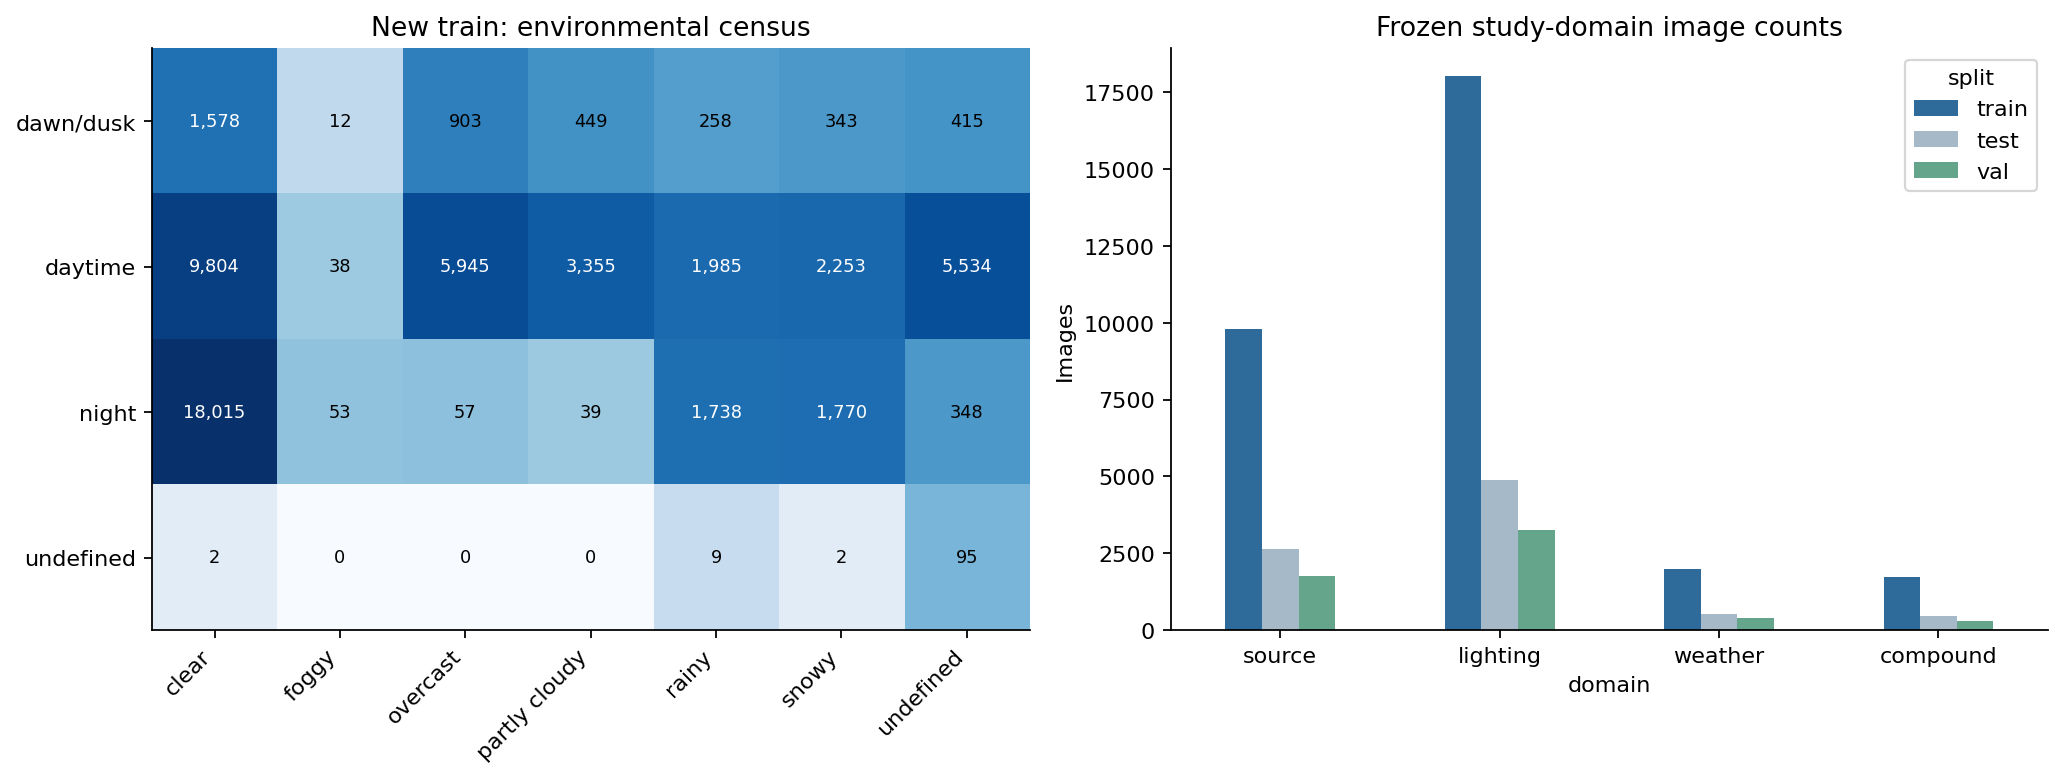

Common target pool: 1738


In [3]:
domains = table('study_domains.csv')
display(domains)
figure('01_domains.png')
print('Common target pool:', int(domains.loc[domains.domain != 'source', 'train'].min()))

## 3. Lớp và đối tượng mỗi ảnh

Xem cả số bbox và số ảnh chứa lớp. Class order được ghi trong metadata; person/bike/motor đã chuẩn hóa thành pedestrian/bicycle/motorcycle. Bảng dựa trên bbox hợp lệ trong EDA.

domain,compound,lighting,source,weather
class,,,,
bicycle,91,990,1304,218
bus,183,1383,2126,491
car,15136,165378,109545,19707
motorcycle,30,444,728,65
pedestrian,980,12265,13170,3249
rider,45,579,980,109
traffic light,5812,53397,20606,5957
traffic sign,5159,58543,34675,6482
train,2,17,28,8


,split,domain,count,mean,median,max
0,train,compound,1738,15.983,15.0,56
1,train,lighting,18015,16.450,15.0,91
3,train,source,9804,19.273,18.0,78
4,train,weather,1985,18.916,18.0,77
5,val,compound,286,16.612,15.0,47
6,val,lighting,3274,16.569,16.0,54
8,val,source,1764,19.334,18.0,61
9,val,weather,396,18.747,17.0,47


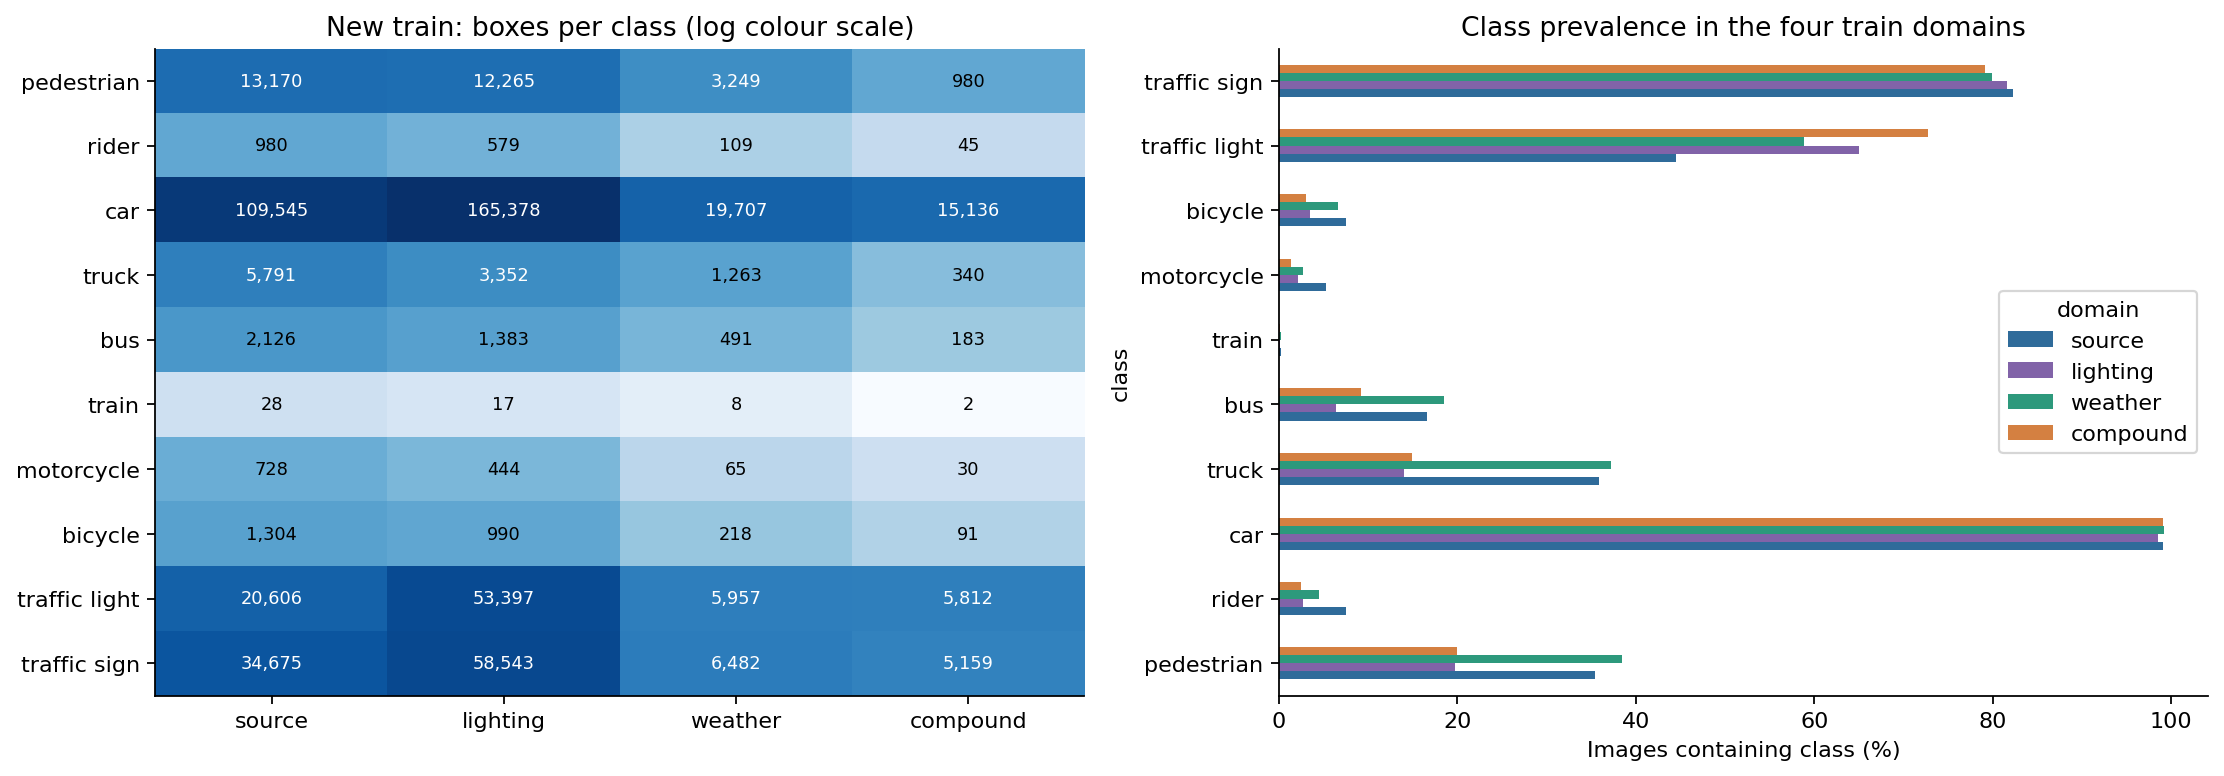

,domain,class,positive_images,boxes
51,compound,rider,15,19
53,compound,truck,53,72
54,compound,bus,21,22
55,compound,train,1,1
56,compound,motorcycle,10,10
57,compound,bicycle,11,15
61,lighting,rider,87,98
65,lighting,train,3,3
66,lighting,motorcycle,68,81
85,source,train,2,2


100 bbox là mốc mô tả EDA; chưa chọn reliable-class metric cho test.


In [4]:
support = table('class_support.csv')
display(support.query("split == 'train' and domain != 'other'").pivot(index='class', columns='domain', values='boxes').fillna(0).astype(int))
display(table('objects_per_image.csv').query("domain != 'other'"))
figure('02_classes.png')
display(support.query("split == 'val' and domain != 'other' and boxes < 100")[[ 'domain','class','positive_images','boxes']])
print('100 bbox là mốc mô tả EDA; chưa chọn reliable-class metric cho test.')

## 4. Scene và thành phần lớp

Các điều kiện thời điểm/thời tiết có thể kèm thay đổi scene và class mix. JSD mô tả sự khác nhau về thành phần; không đo độ khó hay mức giảm mAP.

,domain,city street,gas stations,highway,parking lot,residential,tunnel,undefined
0,source,0.532946,0.000510,0.287026,0.006732,0.170849,0.000102,0.001836
1,lighting,0.658507,0.000278,0.268943,0.003109,0.062115,0.000278,0.006772
2,weather,0.647859,0.001008,0.213098,0.005038,0.127456,0.001008,0.004534
3,compound,0.704258,0.000000,0.220944,0.002301,0.055811,0.000575,0.016110


,target,scene_js_divergence_bits,class_box_mix_js_divergence_bits
0,lighting,0.025662,0.015098
1,weather,0.011163,0.005765
2,compound,0.039668,0.021289


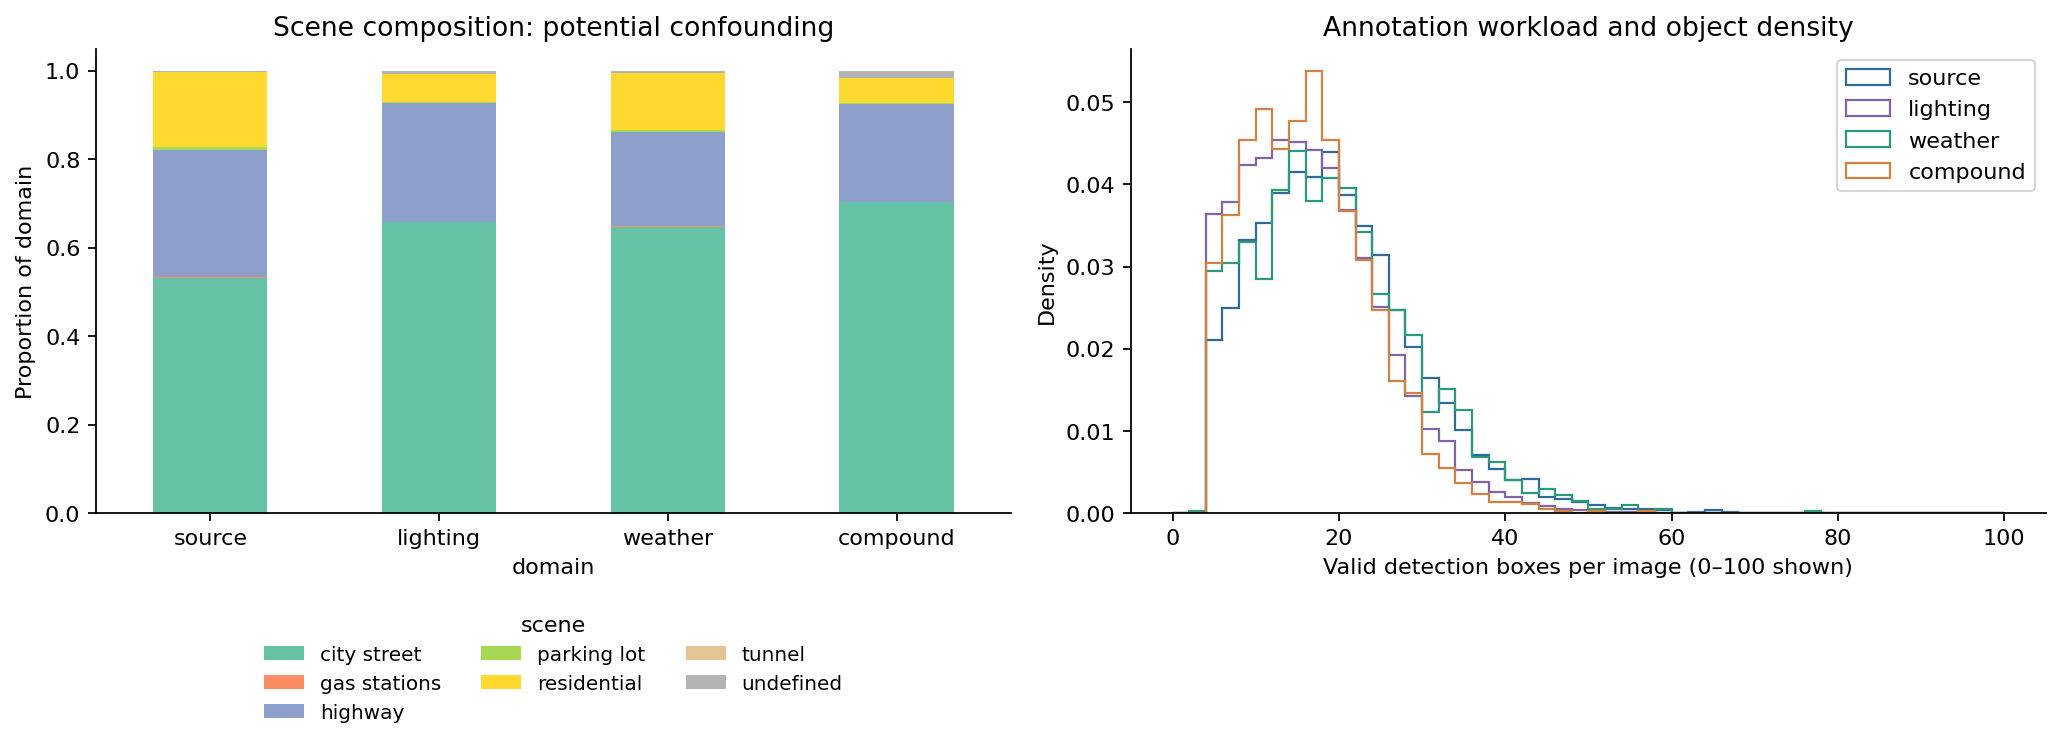

In [5]:
display(table('train_scene_proportions.csv'))
display(table('composition_divergence.csv'))
figure('03_scene_density.png')

## 5. Chất lượng và hình học bbox

Nhãn mới giữ tọa độ gốc. EDA bỏ box malformed/nonfinite/nonpositive, clip biên chỉ khi tính geometry. Mốc 32²/96² tính tại độ phân giải gốc, không tự suy ra AP_small.

,count
train_raw_detection_boxes,1013542
train_out_of_bounds_boxes,0
val_raw_detection_boxes,185526
val_out_of_bounds_boxes,0
train_empty_detection_images,0
val_empty_detection_images,0
train_valid_detection_boxes,1013542
train_malformed_boxes,0
train_nonpositive_boxes,0
train_empty_after_clipping,0


,split,domain,class,boxes,median_area,median_aspect,small_fraction,medium_fraction,large_fraction,occluded_fraction,truncated_fraction
0,train,compound,bicycle,91,4730.5092,1.0000,0.0769,0.6044,0.3187,0.9121,0.0330
1,train,compound,bus,183,10595.8099,1.1714,0.0546,0.4098,0.5355,0.5464,0.2459
2,train,compound,car,15136,1932.7886,1.2500,0.3504,0.4363,0.2133,0.6205,0.0989
3,train,compound,motorcycle,30,2017.7871,0.8889,0.3000,0.5333,0.1667,0.8333,0.1333
4,train,compound,pedestrian,980,1371.9093,0.4103,0.3806,0.5643,0.0551,0.5327,0.0204
5,train,compound,rider,45,3085.6618,0.5088,0.1778,0.5333,0.2889,0.9111,0.0889
6,train,compound,traffic light,5812,275.0592,0.6667,0.8935,0.1056,0.0009,0.0115,0.0200
7,train,compound,traffic sign,5159,461.6805,1.2000,0.7474,0.2365,0.0161,0.0737,0.0209
8,train,compound,train,2,190419.8460,5.5516,0.0000,0.0000,1.0000,0.0000,0.5000
9,train,compound,truck,340,9123.6356,1.1415,0.0676,0.4353,0.4971,0.5794,0.1588


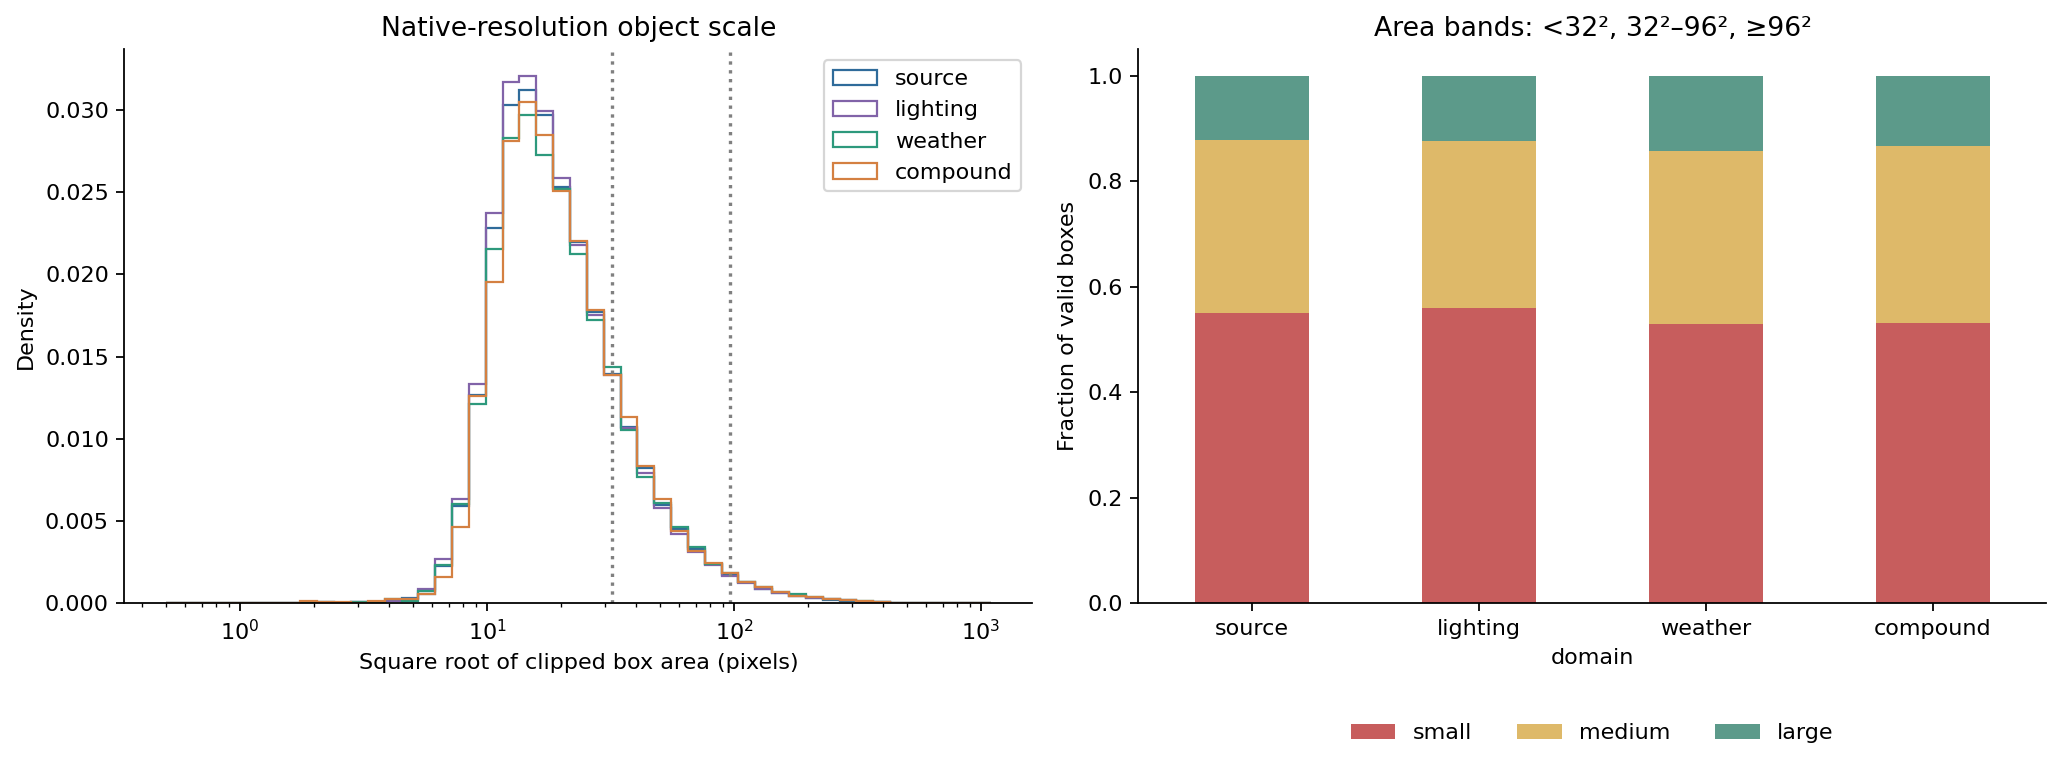

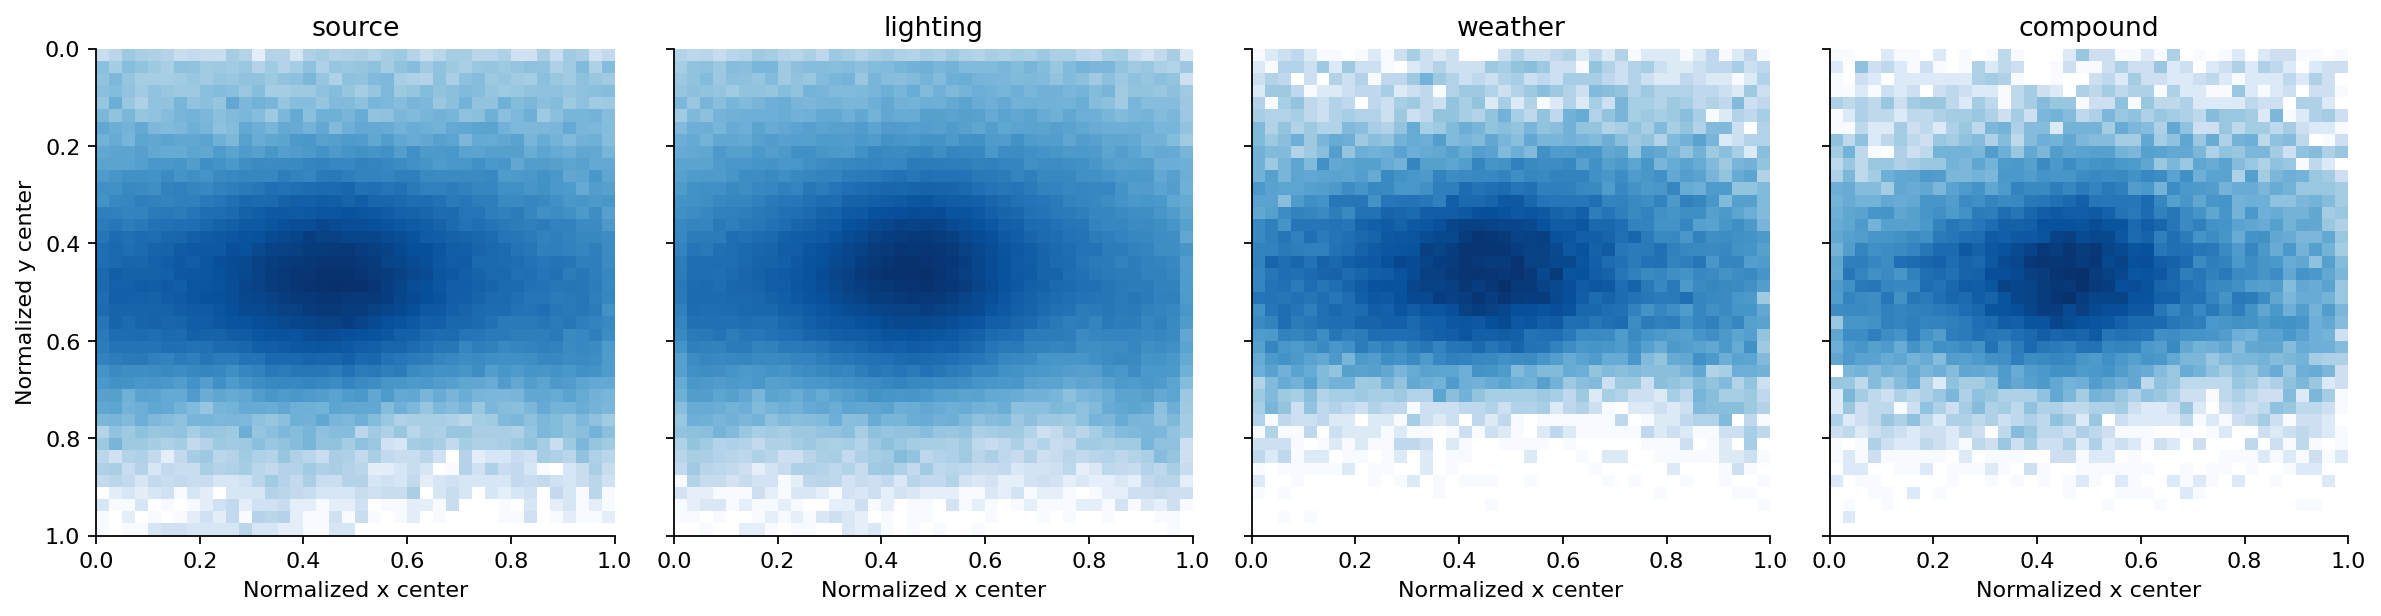

In [6]:
display(pd.Series(summary['annotation_quality'], name='count').to_frame())
display(table('box_geometry.csv').query("split == 'train'").head(20))
figure('04_box_sizes.png')
figure('05_box_centers.png')

## 6. Độ sáng và ảnh ví dụ

Sample cố định 200 ảnh/domain từ train mới, seed 20261001. Grayscale Pillow, resize 320×180, mean/std và tỷ lệ pixel <32. Chỉ là proxy ảnh.

,domain,sample_images,median_gray,median_contrast,median_dark_fraction
0,source,200,102.617,59.359,0.092
1,lighting,200,29.902,31.490,0.678
2,weather,200,103.291,62.614,0.078
3,compound,200,33.678,35.965,0.676


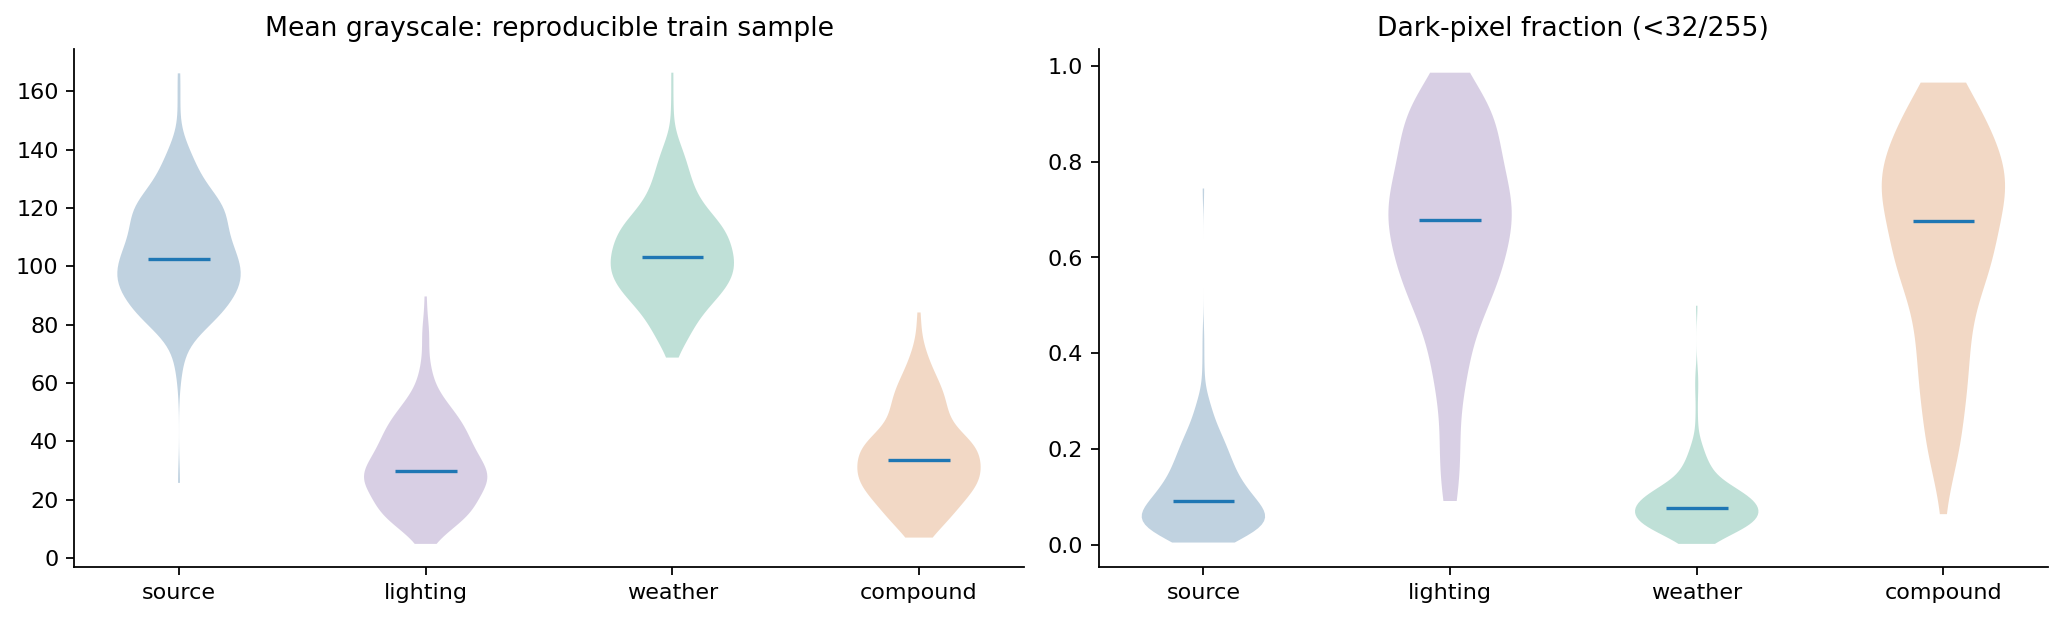

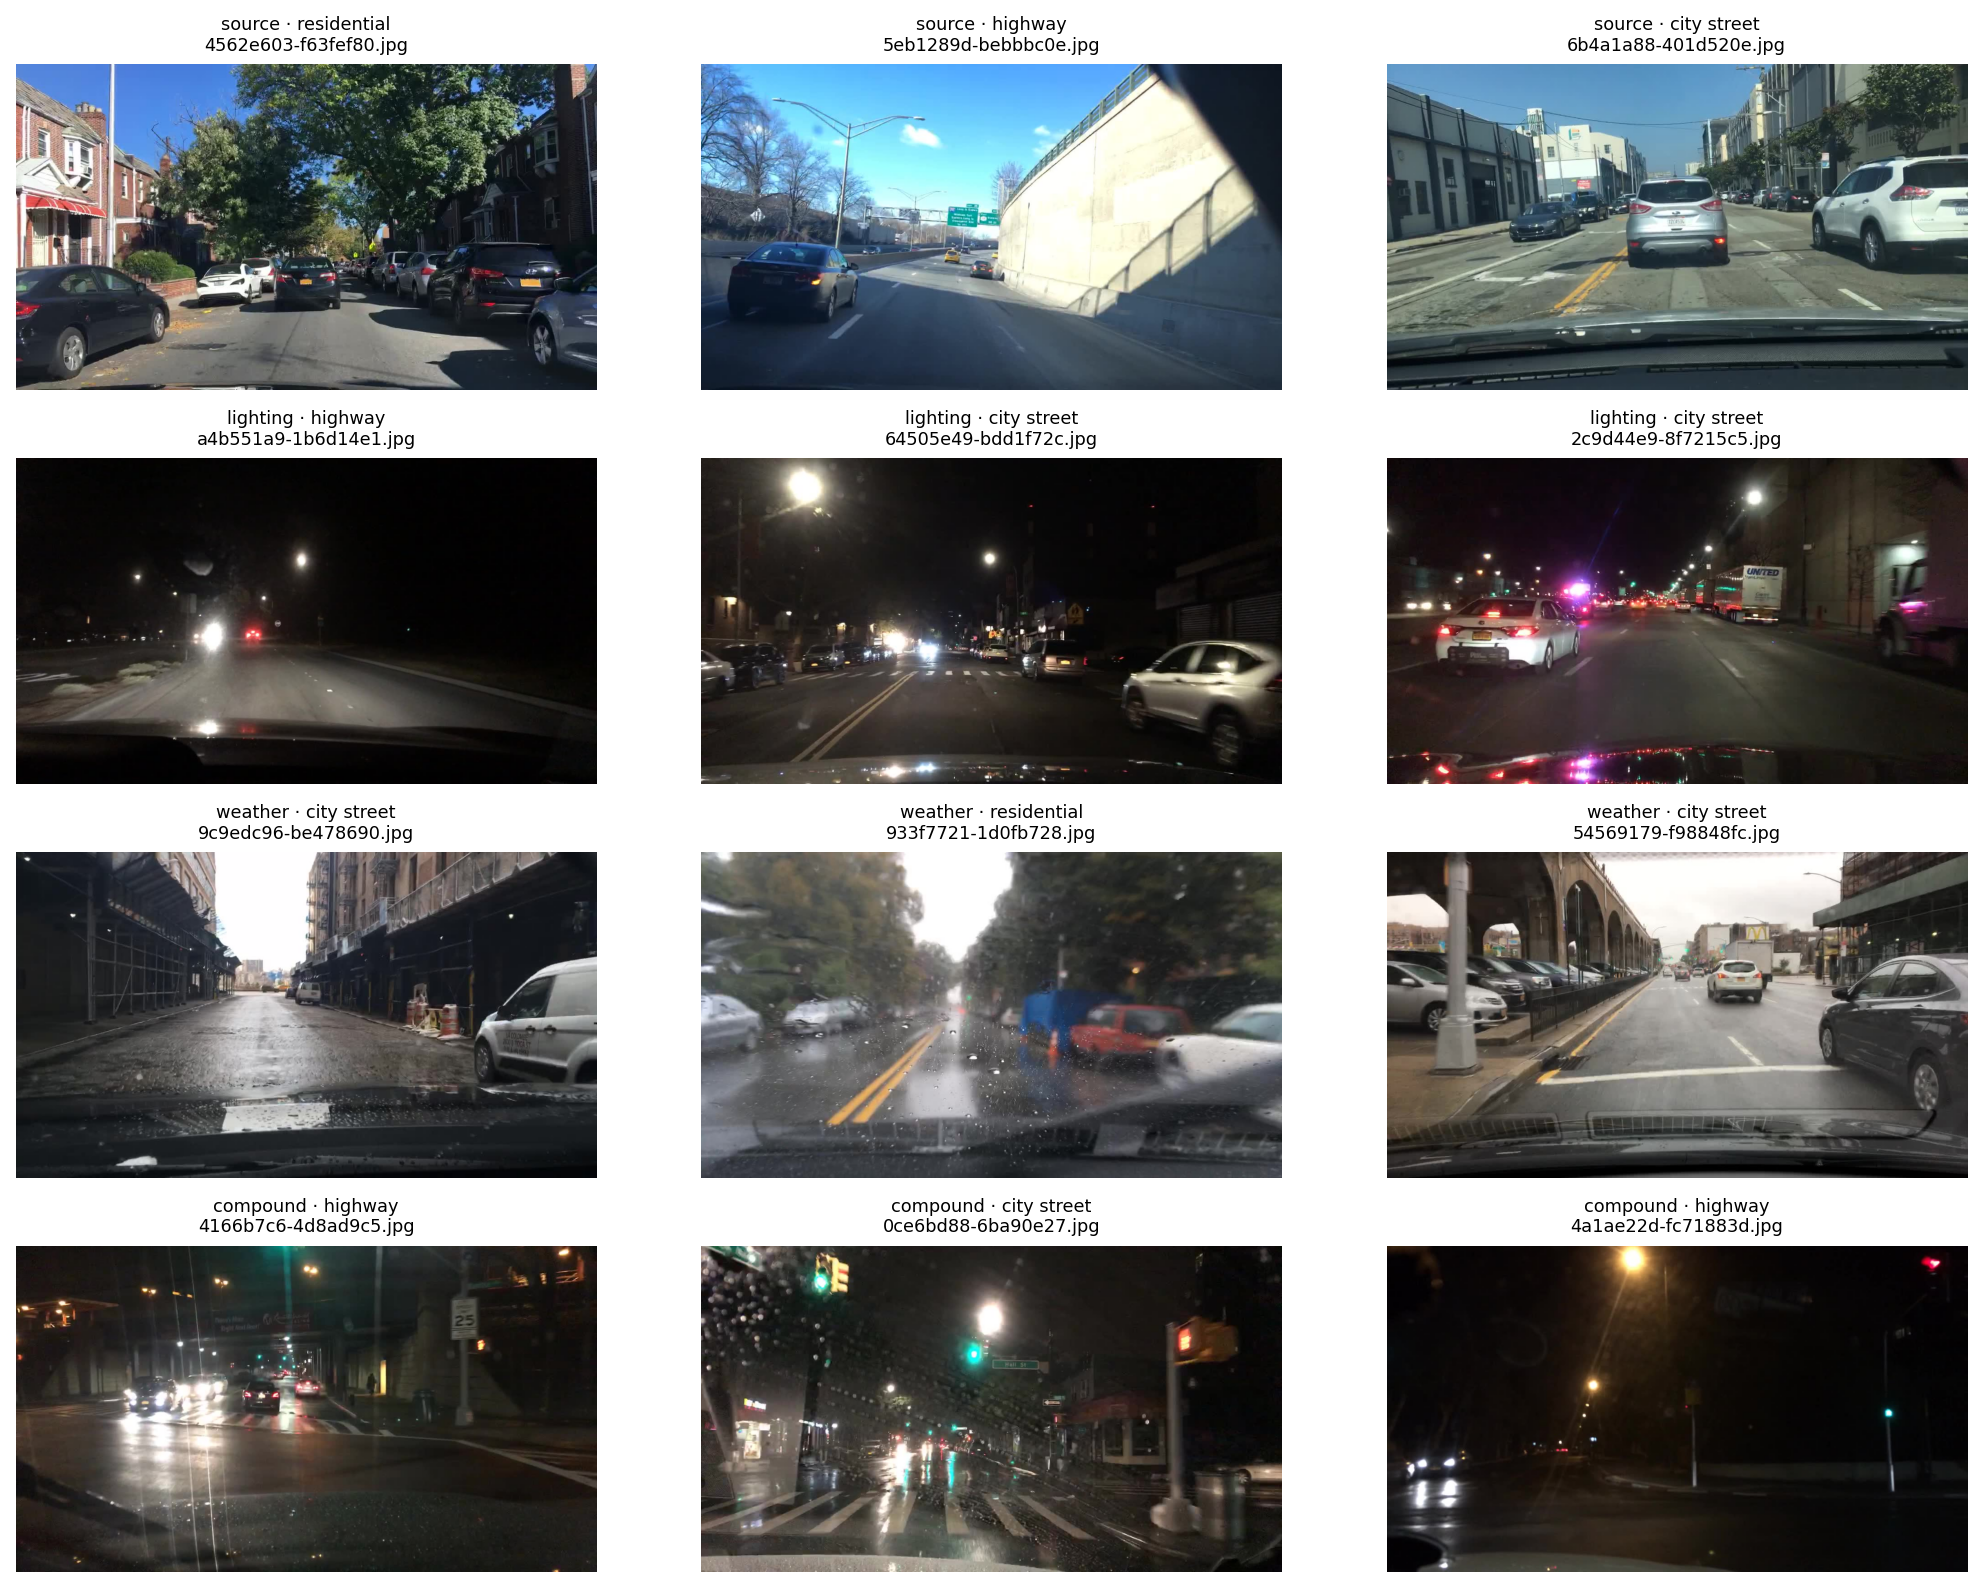

In [7]:
display(table('brightness_summary.csv'))
figure('06_brightness.png')
figure('07_train_examples.png')

## 7. Ngân sách và lớp vắng mặt

Samples lồng nhau cho từng seed 0,1,2, chỉ lấy từ target train. Xác suất vắng lớp chính xác theo lấy mẫu không hoàn lại: `C(M-K,N)/C(M,N)`; K là số ảnh có lớp, không phải số bbox. File membership lưu ảnh của từng rung.

,domain,budget,pool_size,annotation_boxes,missing_classes
0,lighting,10,18015,161,rider; truck; bus; train; motorcycle; bicycle
1,lighting,25,18015,445,rider; bus; train; motorcycle; bicycle
3,lighting,100,18015,1646,train; bicycle
33,weather,10,1985,94,train; motorcycle
34,weather,25,1985,377,train; motorcycle
36,weather,100,1985,1710,train
57,compound,10,1738,128,train; motorcycle; bicycle
58,compound,25,1738,381,motorcycle; bicycle
60,compound,100,1738,1515,NaN


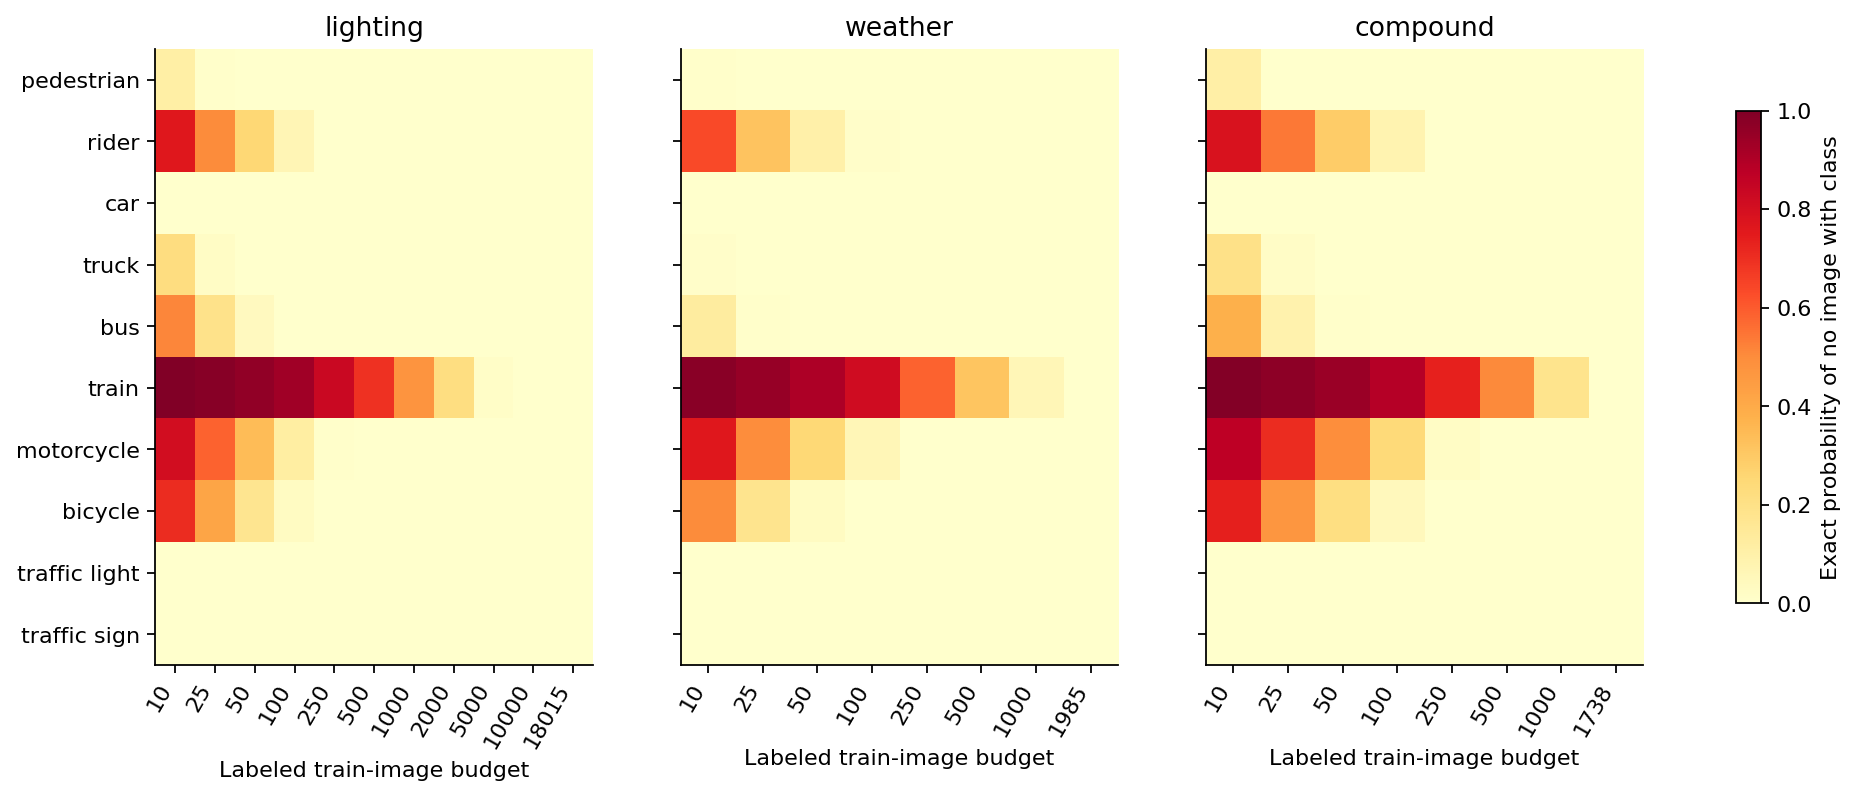

domain,compound,lighting,weather
class,,,
bicycle,0.737,0.704,0.502
bus,0.382,0.515,0.129
car,0.000,0.000,0.000
motorcycle,0.870,0.807,0.758
pedestrian,0.108,0.111,0.008
rider,0.782,0.759,0.635
traffic light,0.000,0.000,0.000
traffic sign,0.000,0.000,0.000
train,0.989,0.993,0.980


Nested memberships verified: True


In [8]:
budgets = table('nested_budget_coverage.csv')
display(budgets.query('seed == 0 and budget in [10,25,100]')[['domain','budget','pool_size','annotation_boxes','missing_classes']])
figure('08_budget_class_coverage.png')
absence = table('class_absence_probability.csv')
display(absence.query('budget == 10').pivot(index='class', columns='domain', values='probability_class_absent').round(3))
print('Nested memberships verified:', summary['budget_memberships_nested'])

## 8. Kết luận và giới hạn

Dataset mới đạt số lượng, membership ảnh–nhãn và kiểm tra không trùng basename/SHA256 giữa các split. EDA mô tả độ phủ lớp, workload, object scale, scene và appearance.

Chưa có kết quả detector, mAP, N_BE/N75/N90. Chưa kiểm tra near-duplicate hoặc group phụ thuộc theo video/địa lý. Cần cố định metric, preprocessing và schedule trước pilot. Dataset mới và manifest SHA256 là phiên bản cố định; seed đơn lẻ không xác định được một split lịch sử dùng thuật toán khác.

In [9]:
print('Source:', metadata['source_dataset'])
print('Kaggle version:', metadata['source_version'])
print('Manifest SHA256:')
display(pd.Series(metadata['manifest_sha256'], name='sha256').to_frame())
print('Report:', EDA / 'report_vi.html')
print('No held-out detection-label EDA:', not summary['heldout_labels_opened_by_eda'])

Source: https://www.kaggle.com/datasets/solesensei/solesensei_bdd100k
Kaggle version: 2
Manifest SHA256:


,sha256
train,08658a692f34f09f8e7f5bce120b2c772eaa653d542d1b...
test,355aa96dc6ed819a2fa4fc2d43351bc1f93131eca0c15e...
val,7a3c67ac9a168bf1ed994c6052263a5b9343679f95fe57...


Report: D:\cv\runs\eda_revised\report_vi.html
No held-out detection-label EDA: True
